# Import / CSV

In [1]:
import pandas as pd

df = pd.read_csv("cleaned_dataset.csv", sep=";")

# Préparer les données

**Valeur extreme retard**

In [2]:
def mois_to_saison(mois):
    if mois in [12, 1, 2]:
        return 0
    elif mois in [3, 4, 5]:
        return 1
    elif mois in [6, 7, 8]:
        return 2
    else:
        return 3

**Année**

In [3]:
df["Annee"] = df["Annee"] - df["Annee"].min()

**Gare de départ**

In [4]:
freq_depart = df["Gare de départ"].value_counts(normalize=True)


df["Gare de départ encodée"] = df["Gare de départ"].map(freq_depart)

**Gare d'Arrivée**

In [5]:
freq_arrivee = df["Gare d'arrivée"].value_counts(normalize=True)
df["Gare d'arrivée encodée"] = df["Gare d'arrivée"].map(freq_arrivee)
target = ["Retard moyen de tous les trains à l'arrivée"]

df["Saison"] = df["Mois"].apply(mois_to_saison)
retard_histo = df.groupby(["Gare de départ encodée", "Gare d'arrivée encodée"])[
    target
].transform("mean")
df["Retard_historique_ligne"] = retard_histo


df["Ligne"] = (
    df["Gare de départ encodée"].astype(str)
    + "_"
    + df["Gare d'arrivée encodée"].astype(str)
)

retard_histo = df.groupby("Ligne")["Retard moyen de tous les trains à l'arrivée"].mean()

df["Retard_historique_ligne"] = df["Ligne"].map(retard_histo)


retard_histo_mois = df.groupby(["Ligne", "Mois"])[
    "Retard moyen de tous les trains à l'arrivée"
].mean()

df["Retard_historique_ligne_mois"] = df.apply(
    lambda x: retard_histo_mois.loc[(x["Ligne"], x["Mois"])], axis=1
)

df["Retard_moyen_dep_histo"] = df.groupby("Ligne")[
    "Retard moyen des trains en retard au départ"
].transform("mean")


df["Annules_histo"] = df.groupby("Ligne")["Nombre de trains annulés"].transform("mean")


df["Retard_cause_externe_histo"] = df.groupby("Ligne")[
    "Prct retard pour causes externes"
].transform("mean")

**Service**

In [6]:
train_service = {"National": 1, "International": 0}
df["Service"] = df["Service"].map(train_service)

# Model regression

**Séparation entrainement / test**

In [7]:
from sklearn.model_selection import train_test_split

features = [
    "Annee",
    "Durée moyenne du trajet",
    "Service",
    "Mois",
    #      "Saison", 'Retard_historique_ligne', 'Retard_historique_ligne_mois', 'Retard_moyen_dep_histo' , 'Annules_histo' ,
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard au départ",
    "Retard moyen des trains en retard au départ",
    "Retard moyen de tous les trains au départ",
    # "Nombre de trains en retard à l'arrivée",
    # "Retard moyen des trains en retard à l'arrivée",
    "Nombre trains en retard > 15min",
    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
    "Nombre trains en retard > 30min",
    "Nombre trains en retard > 60min",
    # "Prct retard pour causes externes",
    # "Prct retard pour cause infrastructure",
    # "Prct retard pour cause gestion trafic",
    # "Prct retard pour cause matériel roulant",
    # "Prct retard pour cause gestion en gare et réutilisation de matériel",
    # "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
    "Gare d'arrivée encodée",
    "Gare de départ encodée",
]


X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

**Entrainement avec 80% des données**

In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


**Model 02**

In [9]:
from sklearn.ensemble import RandomForestRegressor

features2 = [
    "Annee",
    "Durée moyenne du trajet",
    "Service",
    "Mois",
    "Saison",
    "Retard_historique_ligne",
    "Retard_historique_ligne_mois",
    "Retard_moyen_dep_histo",
    "Annules_histo",
    #    "Nombre de circulations prévues",
    #    "Nombre de trains annulés",
    #    "Nombre de trains en retard au départ",
    #    "Retard moyen des trains en retard au départ",
    #    "Retard moyen de tous les trains au départ",
    # "Nombre de trains en retard à l'arrivée",
    # "Retard moyen des trains en retard à l'arrivée",
    #    "Nombre trains en retard > 15min",
    #    "Retard moyen trains en retard > 15 (si liaison concurrencée par vol)",
    #    "Nombre trains en retard > 30min", "Nombre trains en retard > 60min",
    # "Prct retard pour causes externes",
    # "Prct retard pour cause infrastructure",
    # "Prct retard pour cause gestion trafic",
    # "Prct retard pour cause matériel roulant",
    # "Prct retard pour cause gestion en gare et réutilisation de matériel",
    # "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
    "Gare d'arrivée encodée",
    "Gare de départ encodée",
]


X2 = df[features2]
y2 = df[target]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

model2 = RandomForestRegressor(n_estimators=200, max_depth=20, random_state=42)

model2.fit(X_train2, y_train2)
y_pred2 = model2.predict(X_test2)

/home/koussawally/Epitech/picsine/.venv/lib/python3.12/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


**Model 03**

In [10]:
from sklearn.ensemble import RandomForestRegressor

model3 = RandomForestRegressor(n_estimators=200, max_depth=20, random_state=42)

model3.fit(X_train, y_train)
y_pred3 = model3.predict(X_test)

/home/koussawally/Epitech/picsine/.venv/lib/python3.12/site-packages/sklearn/base.py:1336: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


**Model 04**

In [11]:
import xgboost as xgb

model4 = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)

model4.fit(X_train, y_train)

y_pred4 = model4.predict(X_test)

**Prédicitons**

In [12]:
y_pred = model.predict(X_test)

## Evalution

**Best parameters**

In [13]:
from sklearn.model_selection import GridSearchCV

y = y.values.ravel()
# param_grid = {
#     "n_estimators": [50, 100, 200],
#     "max_depth": [5, 10, 20]
# }

# grid = GridSearchCV(
#     estimator=RandomForestRegressor(),
#     param_grid=param_grid,
#     scoring="neg_mean_squared_error",
#     cv=5
# )

# grid.fit(X, y)

# print(grid.best_params_)
# print(grid.best_score_)

**R2 (Précision)**

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_test = y_test.loc[X_test.index]

print("Model Linéaire")
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))
print()
print("Model Random Tree Moins de Colonnes")
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred2)))
print("MAE:", mean_absolute_error(y_test, y_pred2))
print("R²:", r2_score(y_test, y_pred2))
print()
print("Model Random Tree")
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred3)))
print("MAE:", mean_absolute_error(y_test, y_pred3))
print("R²:", r2_score(y_test, y_pred3))
print()
print("Model XGBRegressor")
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred4)))
print("MAE:", mean_absolute_error(y_test, y_pred4))
print("R²:", r2_score(y_test, y_pred4))


# coefficients = model.coef_.flatten()

# coeff_df = pd.DataFrame({
#     'Feature': X.columns,
#     'Poids': coefficients
# })
# coeff_df = coeff_df.sort_values(by="Poids", ascending=False)
# print(coeff_df)
# print(y_pred[:10])
# print(y_test[:10])

Model Linéaire
RMSE : 2.5931384070264976
MAE: 1.6900830928661483
R²: 0.613063413943421

Model Random Tree Moins de Colonnes
RMSE : 2.913943609408452
MAE: 2.01818774342883
R²: 0.5114031232242575

Model Random Tree
RMSE : 1.7767829860063016
MAE: 1.0703323778570188
R²: 0.8183408933262022

Model XGBRegressor
RMSE : 1.786487909040685
MAE: 1.027944564819336
R²: 0.8163509964942932


**Nouvelle évalutation plus robuste :**

In [15]:
# from sklearn.model_selection import cross_validate
# y2 = y2.values.ravel()
# scoring = {
#     "rmse": "neg_root_mean_squared_error",
#     "mae": "neg_mean_absolute_error",
#     "r2": "r2"
# }

# results = cross_validate(model, X, y, cv=5, scoring=scoring)

# print("RMSE :", -results["test_rmse"].mean())
# print("MAE  :", -results["test_mae"].mean())
# print("R2   :", results["test_r2"].mean())


# results2 = cross_validate(model2, X2, y2, cv=5, scoring=scoring)

# print("RMSE :", -results2["test_rmse"].mean())
# print("MAE  :", -results2["test_mae"].mean())
# print("R2   :", results2["test_r2"].mean())


# results3 = cross_validate(model3, X, y, cv=5, scoring=scoring)

# print("RMSE :", -results3["test_rmse"].mean())
# print("MAE  :", -results3["test_mae"].mean())
# print("R2   :", results3["test_r2"].mean())


# results4 = cross_validate(model4, X, y, cv=5, scoring=scoring)

# print("RMSE :", -results4["test_rmse"].mean())
# print("MAE  :", -results4["test_mae"].mean())
# print("R2   :", results4["test_r2"].mean())

# Exporter les model

In [16]:
import joblib

joblib.dump(model, "model.pkl")
joblib.dump(model2, "modele_random_tree_low.pkl")
joblib.dump(model3, "modele_random_tree_huge.pkl")
joblib.dump(model4, "modele_XGB_Regressor.pkl")

['modele_XGB_Regressor.pkl']

# Shématiser pour mieux comprendre

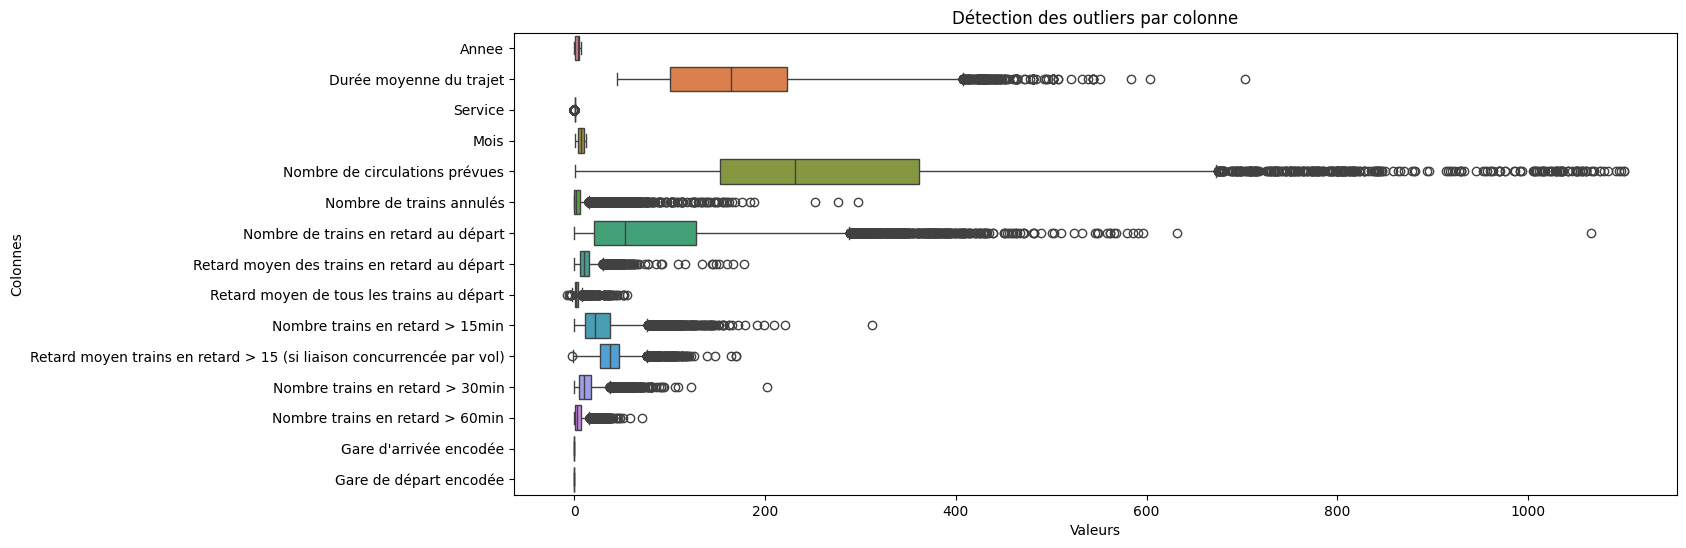

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# corr = df.corr(numeric_only=True)

# plt.figure(figsize=(12,10))
# sns.heatmap(corr, cmap="coolwarm")
# plt.show()

plt.figure(figsize=(15, 6))

sns.boxplot(data=X, orient="h")

plt.title("Détection des outliers par colonne")
plt.xlabel("Valeurs")
plt.ylabel("Colonnes")
plt.show()

**Baseline**

In [18]:
y_pred_baseline = np.full_like(y_test, y_train.mean())

mse = mean_squared_error(y_test, y_pred_baseline)
rmse = np.sqrt(mse)
print("MAE:", mean_absolute_error(y_test, y_pred_baseline))
print("RMSE baseline :", rmse)
print("R²:", r2_score(y_test, y_pred_baseline))

MAE: 3.0845160612501985
RMSE baseline : 4.169287444852983
R²: -0.00025809833191825504


In [19]:
import numpy as np
from sklearn.metrics import mean_squared_error

# Supposons que y_test contient les vrais retards
n = len(y_test)

# Prédictions aléatoires entre 0 et 10
y_pred_random = np.random.uniform(0, 10, size=n)

# Évaluer
rmse2 = np.sqrt(mean_squared_error(y_test, y_pred_random))
print("MAE:", mean_absolute_error(y_test, y_pred_random))
print("RMSE baseline :", rmse2)
print("R²:", r2_score(y_test, y_pred_random))

MAE: 3.8927241318778596
RMSE baseline : 5.132935702338612
R²: -0.5160727739833153


# Les stats de la baseline :


**RMSE baseline :** 5.139942610616193


**MAE:** 3.87093590838757

**R²:** -0.520214744246897

# Les Stats du model linéaire (avec toutes les colonnes)

**RMSE :** 2.8352364365771208


**MAE :** 1.9789858869808508

**R2 :** 0.49017238158540266

# Model Random Forest (avec peu de colonne)

**RMSE :** 3.377982735667301


**MAE :** 2.424343600093451


**R2 :** 0.2813771991392753

# Model Random Forest (avec plus de colonnes)

**RMSE :** 1.9480780035253975


**MAE  :** 1.1960627054853898


**R2 :** 0.7575526174175122

# Model XGB Regressor

**RMSE :** 1.975102621782101


**MAE  :** 1.1999307406583104


**R2   :** 0.7508489377911736